# Don't Miss the Battery: E2 safety-aware training (Faster R-CNN)
**Group 3 (Bhavyasree Kondi, Bhoomika Lnu, Sanjana Reddy Katham, Sharan Somshekhar Patil), DATA-255**

Trains five Faster R-CNN ResNet-50-FPN variants on the same leak-free split and compares them on the
safety metrics:

| Variant | Box-classifier loss | Sampling |
|---|---|---|
| `baseline` | cross-entropy | uniform |
| `class_balanced` | cross-entropy weighted by effective number of samples (Cui et al., 2019) | uniform |
| `focal` | focal loss, gamma = 2 (Lin et al., 2017) | uniform |
| `repeat_factor` | cross-entropy | repeat-factor sampling (Gupta et al., 2019) |
| `focal_rfs` | focal loss | repeat-factor sampling |

All variants get the same iteration budget. Operating thresholds are chosen on **validation** and applied
once to **test**. Missed-battery rates come with 95% bootstrap intervals that resample whole batteries.

**Before running:** Runtime > Change runtime type > T4 GPU, then Runtime > Run all (~1.5 h).
Each finished variant is saved to Drive, so after a disconnect, Run all again and it continues where it stopped.

In [1]:
# ---- Config ----
SEED = 42
EPOCHS = 6           # same budget as the intermediate-report baseline (val mAP flat from epoch 4)
BATCH_SIZE = 4
LR = 0.005
IMG_SIZE = 640
IOU_MATCH = 0.5
TARGET_PRECISION = 0.90
MISS_COST = 10
COST_RATIOS = list(range(1, 21))
N_BOOT = 1000
CB_BETA = 0.999      # class-balanced loss
FOCAL_GAMMA = 2.0
VARIANTS = {
    "baseline":       {"loss": "ce",    "rfs": False},
    "class_balanced": {"loss": "cb",    "rfs": False},
    "focal":          {"loss": "focal", "rfs": False},
    "repeat_factor":  {"loss": "ce",    "rfs": True},
    "focal_rfs":      {"loss": "focal", "rfs": True},
}
DATA_URL = "https://zenodo.org/api/records/15490523/files/recybat24.tar.gz/content"
ROOT = "/content/recybat24"

import os, json, random, time, glob, re, tarfile, math, contextlib, io, urllib.request, shutil
from collections import defaultdict, Counter
import numpy as np
import torch, torchvision
import torch.nn.functional as F
import matplotlib.pyplot as plt

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", dev)
if dev.type == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device cuda
Tesla T4


In [2]:
# ---- Output folder: Google Drive if available, else local disk (zipped for download at the end) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/dont_miss_the_battery/E2_safety"
except ImportError:
    OUT = "./outputs/E2_safety"
except Exception as e:
    print(f"Drive mount failed ({e}); saving locally instead. Results will be downloaded as a zip at the end.")
    OUT = "/content/outputs/E2_safety"
os.makedirs(OUT, exist_ok=True)
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
print("Outputs ->", OUT)

Mounted at /content/drive
Outputs -> /content/drive/MyDrive/dont_miss_the_battery/E2_safety


In [3]:
# ---- Download + extract RecyBat24 (Zenodo record 15490523, CC BY-NC-ND 4.0) ----
if not os.path.exists(os.path.join(ROOT, ".done")):
    os.makedirs(ROOT, exist_ok=True)
    tgz = "/content/recybat24.tar.gz"
    if not os.path.exists(tgz):
        print("Downloading ~263 MB ...")
        urllib.request.urlretrieve(DATA_URL, tgz)
    with tarfile.open(tgz) as t:
        try:
            t.extractall(ROOT, filter="data")
        except TypeError:
            t.extractall(ROOT)
    open(os.path.join(ROOT, ".done"), "w").close()

# ---- Detection annotations (the instance-segmentation file repeats every battery 3x, so skip it) ----
coco_files = {}
for p in glob.glob(ROOT + "/**/*.json", recursive=True):
    low = p.lower()
    if "segmentation" in os.path.basename(low):
        continue
    try:
        d = json.load(open(p))
    except Exception:
        continue
    if isinstance(d, dict) and {"images", "annotations", "categories"} <= d.keys():
        if "train" in low:
            coco_files["train"] = p
        elif "val" in low:
            coco_files["val"] = p
assert {"train", "val"} <= coco_files.keys(), coco_files
coco = {k: json.load(open(v)) for k, v in coco_files.items()}
for k, d in coco.items():
    print(k, "| images:", len(d["images"]), "| boxes:", len(d["annotations"]))

img_index = defaultdict(list)
for p in glob.glob(ROOT + "/**/*", recursive=True):
    if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
        img_index[os.path.basename(p)].append(p)

def resolve(file_name, split):
    direct = os.path.join(os.path.dirname(coco_files[split]), file_name)
    if os.path.exists(direct):
        return direct
    cands = img_index.get(os.path.basename(file_name), [])
    for c in cands:
        if split in c.lower():
            return c
    if cands:
        return cands[0]
    raise FileNotFoundError(file_name)

used = sorted({a["category_id"] for s in coco.values() for a in s["annotations"]})
cat_names = {c["id"]: c["name"] for c in coco["train"]["categories"]}
cat2label = {cid: i + 1 for i, cid in enumerate(used)}            # 0 = background
CLASSES = ["__background__"] + [cat_names.get(cid, str(cid)) for cid in used]
K = len(CLASSES) - 1
print("Classes:", CLASSES[1:])

val | images: 1407 | boxes: 1434
train | images: 1421 | boxes: 1437
Classes: ['cylindric', 'pouch', 'prismatic']


In [4]:
# ---- Leak-free split (identical to the intermediate report): released val -> val + test by battery ----
# File names: 26_2_3_cyl.jpg or 42_5_F_2_po.jpg (F/R = side). Battery ID = number + type.
GROUP_REGEX = r"^(\d+)_\d+_(?:[A-Za-z]_)?\d+_([A-Za-z]+)"

def battery_id(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    m = re.search(GROUP_REGEX, stem)
    return "_".join(m.groups()) if m else stem

from sklearn.model_selection import StratifiedGroupKFold
val_imgs = coco["val"]["images"]
groups = [battery_id(i["file_name"]) for i in val_imgs]
types = [g.rsplit("_", 1)[-1] for g in groups]
vi, ti = next(StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED).split(val_imgs, types, groups=groups))
val_ids = [val_imgs[i]["id"] for i in vi]
test_ids = [val_imgs[i]["id"] for i in ti]
assert not ({groups[i] for i in vi} & {groups[i] for i in ti})
print(f"val {len(val_ids)} imgs / {len({groups[i] for i in vi})} batteries | "
      f"test {len(test_ids)} imgs / {len({groups[i] for i in ti})} batteries")
json.dump({"val_ids": val_ids, "test_ids": test_ids, "seed": SEED}, open(os.path.join(OUT, "split.json"), "w"))

val 702 imgs / 47 batteries | test 705 imgs / 47 batteries


In [5]:
# ---- Dataset ----
from torchvision.io import read_image, ImageReadMode

class BatteryDet(torch.utils.data.Dataset):
    def __init__(self, split, img_ids=None, train=False):
        d = coco[split]
        self.split, self.train = split, train
        self.imgs = {i["id"]: i for i in d["images"]}
        self.ids = list(img_ids) if img_ids is not None else list(self.imgs)
        self.anns = defaultdict(list)
        for a in d["annotations"]:
            self.anns[a["image_id"]].append(a)

    def __len__(self):
        return len(self.ids)

    def gt(self, iid):
        boxes, labels = [], []
        for a in self.anns[iid]:
            x, y, w, h = a["bbox"]
            if w >= 1 and h >= 1:
                boxes.append([x, y, x + w, y + h]); labels.append(cat2label[a["category_id"]])
        return np.array(boxes, np.float32).reshape(-1, 4), np.array(labels, np.int64)

    def battery(self, iid):
        return battery_id(self.imgs[iid]["file_name"])

    def __getitem__(self, i):
        iid = self.ids[i]
        img = read_image(resolve(self.imgs[iid]["file_name"], self.split), ImageReadMode.RGB).float() / 255
        boxes, labels = self.gt(iid)
        boxes = torch.from_numpy(boxes)
        if self.train and random.random() < 0.5:
            img = img.flip(-1)
            W = img.shape[-1]
            boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        return img, {"boxes": boxes, "labels": torch.from_numpy(labels), "image_id": torch.tensor(iid)}

def collate(b):
    return tuple(zip(*b))

train_ds = BatteryDet("train", train=True)
val_ds = BatteryDet("val", val_ids)
test_ds = BatteryDet("val", test_ids)
print(len(train_ds), len(val_ds), len(test_ds))

1421 702 705


In [6]:
# ---- Imbalance tools: class-balanced weights and repeat-factor sampling ----
box_counts = Counter(int(l) for iid in train_ds.ids for l in train_ds.gt(iid)[1])
eff = {c: (1 - CB_BETA ** box_counts[c]) / (1 - CB_BETA) for c in range(1, K + 1)}
fg_w = np.array([1 / eff[c] for c in range(1, K + 1)])
fg_w = fg_w / fg_w.mean()
CB_WEIGHTS = torch.tensor([1.0] + fg_w.tolist(), dtype=torch.float32)   # background keeps weight 1
print("Train boxes per class:", {CLASSES[c]: box_counts[c] for c in range(1, K + 1)})
print("Class-balanced weights:", {CLASSES[c]: round(float(CB_WEIGHTS[c]), 3) for c in range(1, K + 1)})

# Repeat factor per image = max over its classes of max(1, sqrt(t / f_c)), f_c = share of images with class c.
# t = frequency of the most common class, so pouch images keep factor 1 and rarer classes are oversampled.
img_classes = {iid: set(train_ds.gt(iid)[1].tolist()) for iid in train_ds.ids}
f_c = {c: sum(c in s for s in img_classes.values()) / len(img_classes) for c in range(1, K + 1)}
t_rfs = max(f_c.values())
r_c = {c: max(1.0, math.sqrt(t_rfs / f_c[c])) if f_c[c] > 0 else 1.0 for c in f_c}
RFS_WEIGHTS = [max([r_c[c] for c in img_classes[iid]], default=1.0) for iid in train_ds.ids]
print("Repeat factors:", {CLASSES[c]: round(r_c[c], 2) for c in r_c})

def make_train_loader(rfs):
    g = torch.Generator().manual_seed(SEED)
    if rfs:   # same number of samples per epoch as uniform sampling -> same iteration budget
        sampler = torch.utils.data.WeightedRandomSampler(RFS_WEIGHTS, num_samples=len(train_ds), replacement=True, generator=g)
        return torch.utils.data.DataLoader(train_ds, BATCH_SIZE, sampler=sampler, num_workers=2,
                                           collate_fn=collate, drop_last=True)
    return torch.utils.data.DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=2,
                                       collate_fn=collate, generator=g, drop_last=True)

# ---- Swap the box-classifier loss inside torchvision's RoI heads ----
import torchvision.models.detection.roi_heads as roi_heads
LOSS = {"mode": "ce"}

def fastrcnn_loss_variant(class_logits, box_regression, labels, regression_targets):
    labels = torch.cat(labels, dim=0)
    regression_targets = torch.cat(regression_targets, dim=0)
    logits = class_logits.float()
    if LOSS["mode"] == "cb":
        cls_loss = F.cross_entropy(logits, labels, weight=CB_WEIGHTS.to(logits.device))
    elif LOSS["mode"] == "focal":
        logp = F.log_softmax(logits, dim=-1).gather(1, labels[:, None]).squeeze(1)
        cls_loss = (-(1 - logp.exp()) ** FOCAL_GAMMA * logp).mean()
    else:
        cls_loss = F.cross_entropy(logits, labels)
    # box regression term unchanged from torchvision
    pos = torch.where(labels > 0)[0]
    N = class_logits.shape[0]
    box_regression = box_regression.reshape(N, box_regression.size(-1) // 4, 4)
    box_loss = F.smooth_l1_loss(box_regression[pos, labels[pos]], regression_targets[pos],
                                beta=1 / 9, reduction="sum") / labels.numel()
    return cls_loss, box_loss

roi_heads.fastrcnn_loss = fastrcnn_loss_variant

Train boxes per class: {'cylindric': 239, 'pouch': 868, 'prismatic': 330}
Class-balanced weights: {'cylindric': 1.413, 'pouch': 0.518, 'prismatic': 1.069}
Repeat factors: {'cylindric': 1.97, 'pouch': 1.0, 'prismatic': 1.62}


In [7]:
# ---- Model + evaluation helpers ----
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou, nms
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def build_model():
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT, min_size=IMG_SIZE, max_size=IMG_SIZE)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, K + 1)
    m.roi_heads.score_thresh = 0.001
    m.roi_heads.detections_per_img = 100
    return m.to(dev)

def make_gt(ds):
    images, anns = [], []
    for iid in ds.ids:
        info = ds.imgs[iid]
        images.append({"id": iid, "width": info.get("width", IMG_SIZE), "height": info.get("height", IMG_SIZE)})
        b, l = ds.gt(iid)
        for bb, ll in zip(b, l):
            w, h = float(bb[2] - bb[0]), float(bb[3] - bb[1])
            anns.append({"id": len(anns) + 1, "image_id": iid, "category_id": int(ll),
                         "bbox": [float(bb[0]), float(bb[1]), w, h], "area": w * h, "iscrowd": 0})
    c = COCO()
    c.dataset = {"images": images, "annotations": anns,
                 "categories": [{"id": i, "name": n} for i, n in enumerate(CLASSES) if i > 0]}
    with contextlib.redirect_stdout(io.StringIO()):
        c.createIndex()
    return c

@torch.no_grad()
def predict(model, ds, bs=8):
    model.eval()
    loader = torch.utils.data.DataLoader(ds, bs, shuffle=False, num_workers=2, collate_fn=collate)
    preds = {}
    for imgs, tgts in loader:
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            out = model([im.to(dev) for im in imgs])
        for t, o in zip(tgts, out):
            preds[int(t["image_id"])] = {k: v.float().cpu().numpy() for k, v in o.items()}
    return preds

def coco_metrics(preds, gt):
    res = [{"image_id": iid, "category_id": int(l), "score": float(s),
            "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]}
           for iid, p in preds.items() for b, s, l in zip(p["boxes"], p["scores"], p["labels"])]
    if not res:
        return {"mAP50_95": 0.0, "mAP50": 0.0, "mAP75": 0.0, "per_class": {}}
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(res), "bbox"); E.evaluate(); E.accumulate(); E.summarize()
    prec = E.eval["precision"]             # [IoU, recall, class, area, maxDets]
    ap = lambda p: float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    per_class = {CLASSES[k + 1]: {"AP50_95": ap(prec[:, :, k, 0, -1]), "AP50": ap(prec[0, :, k, 0, -1])} for k in range(K)}
    return {"mAP50_95": float(E.stats[0]), "mAP50": float(E.stats[1]), "mAP75": float(E.stats[2]), "per_class": per_class}

In [8]:
# ---- Safety evaluation ----
THS = np.round(np.arange(0.01, 1.0, 0.01), 2)

def match(preds, ds, class_aware):
    """Greedy score-ordered matching. Because it is greedy in score order, keeping only predictions with
    score >= t gives exactly the matching at threshold t, so per-object results serve every threshold.
    Returns, per ground-truth battery: score of the prediction that caught it (-1 if never caught), its class,
    the class it was predicted as, its battery ID; and per unmatched prediction (false alarm): score, label, battery."""
    G = {"score": [], "cls": [], "pred": [], "bat": []}
    FA = {"score": [], "label": [], "bat": []}
    for iid in ds.ids:
        gb, gl = ds.gt(iid); bat = ds.battery(iid)
        p = preds[iid]; pb, ps, pl = torch.from_numpy(p["boxes"]), torch.from_numpy(p["scores"]), p["labels"]
        if not class_aware and len(pb):   # one box per object for "was a battery found at all"
            keep = nms(pb, ps, 0.5); pb, ps, pl = pb[keep], ps[keep], pl[keep.numpy()]
        ious = box_iou(pb, torch.from_numpy(gb)).numpy() if len(gb) and len(pb) else np.zeros((len(pb), len(gb)))
        g_score = np.full(len(gb), -1.0); g_pred = np.zeros(len(gb), int)
        for j in torch.argsort(ps, descending=True).numpy():
            cand = ious[j].copy(); cand[g_score >= 0] = -1
            if class_aware:
                cand[gl != pl[j]] = -1
            k = int(cand.argmax()) if len(gb) else -1
            if k >= 0 and cand[k] >= IOU_MATCH:
                g_score[k] = float(ps[j]); g_pred[k] = int(pl[j])
            else:
                FA["score"].append(float(ps[j])); FA["label"].append(int(pl[j])); FA["bat"].append(bat)
        G["score"] += g_score.tolist(); G["cls"] += gl.tolist(); G["pred"] += g_pred.tolist(); G["bat"] += [bat] * len(gb)
    return {k: np.array(v) for k, v in G.items()}, {k: np.array(v) for k, v in FA.items()}

def counts(G, FA, t):
    tp = int((G["score"] >= t).sum()); fp = int((FA["score"] >= t).sum()); n = len(G["score"])
    fn = n - tp
    prec = tp / max(tp + fp, 1); rec = tp / max(n, 1)
    return {"thr": float(t), "tp": tp, "fp": fp, "fn": fn, "n": n, "precision": prec, "recall": rec,
            "f1": 2 * prec * rec / max(prec + rec, 1e-9), "miss_rate": fn / max(n, 1)}

def pick_threshold_precision(G, FA):
    """Lowest miss rate with precision >= target (ties -> higher precision). Falls back to best precision."""
    rows = [counts(G, FA, t) for t in THS]
    ok = [r for r in rows if r["precision"] >= TARGET_PRECISION]
    best = min(ok, key=lambda r: (r["miss_rate"], -r["precision"])) if ok else max(rows, key=lambda r: r["precision"])
    return best["thr"]

def pick_threshold_cost(G, FA, c):
    return min(THS, key=lambda t: (lambda r: c * r["fn"] + r["fp"])(counts(G, FA, t)))

def bootstrap_miss(G, FA, t, seed=SEED):
    """95% interval for miss rate and precision, resampling whole batteries (images of one battery are correlated)."""
    bats = np.unique(G["bat"])
    per = {b: (int(((G["bat"] == b) & (G["score"] >= t)).sum()), int((G["bat"] == b).sum()),
               int(((FA["bat"] == b) & (FA["score"] >= t)).sum())) for b in bats}
    rng = np.random.default_rng(seed); miss, prec = [], []
    for _ in range(N_BOOT):
        s = rng.choice(bats, len(bats), replace=True)
        tp = sum(per[b][0] for b in s); n = sum(per[b][1] for b in s); fp = sum(per[b][2] for b in s)
        miss.append(1 - tp / max(n, 1)); prec.append(tp / max(tp + fp, 1))
    out = {"miss_ci": [float(np.percentile(miss, 2.5)), float(np.percentile(miss, 97.5))],
           "precision_ci": [float(np.percentile(prec, 2.5)), float(np.percentile(prec, 97.5))],
           "n_batteries": int(len(bats))}
    if counts(G, FA, t)["fn"] == 0:   # bootstrap of zero events is [0, 0]; give the exact battery-level bound
        out["miss_upper95_zero_events"] = float(1 - 0.05 ** (1 / len(bats)))
    return out

def ece(G, FA, min_score=0.05, bins=10):
    s = np.concatenate([G["score"][G["score"] >= min_score], FA["score"][FA["score"] >= min_score]])
    y = np.concatenate([np.ones((G["score"] >= min_score).sum()), np.zeros((FA["score"] >= min_score).sum())])
    edges = np.linspace(min_score, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        b = (s >= lo) & ((s < hi) | (hi == 1))
        if b.any():
            e += b.mean() * abs(y[b].mean() - s[b].mean())
    return float(e)

def confusion(G, FA, t):
    cm = np.zeros((K + 1, K + 1), int)      # rows = truth (last = background), cols = prediction (last = missed)
    for sc, c, p in zip(G["score"], G["cls"], G["pred"]):
        cm[c - 1, p - 1 if sc >= t else K] += 1
    for sc, l in zip(FA["score"], FA["label"]):
        if sc >= t:
            cm[K, l - 1] += 1
    return cm

def safety_report(val_preds, test_preds):
    rep = {}
    for mode in ["class_agnostic", "class_aware"]:
        Gv, Fv = match(val_preds, val_ds, mode == "class_aware")
        Gt, Ft = match(test_preds, test_ds, mode == "class_aware")
        t90 = pick_threshold_precision(Gv, Fv)
        r = {"thr_from_val": t90, "test_at_thr": counts(Gt, Ft, t90), **bootstrap_miss(Gt, Ft, t90),
             "cost": {}, "ece": ece(Gt, Ft)}
        for c in COST_RATIOS:
            tc = pick_threshold_cost(Gv, Fv, c); ct = counts(Gt, Ft, tc)
            r["cost"][c] = {"thr_from_val": float(tc), "cwe_per_battery": (c * ct["fn"] + ct["fp"]) / max(ct["n"], 1),
                            "miss_rate": ct["miss_rate"], "precision": ct["precision"], "fp": ct["fp"], "fn": ct["fn"]}
        r["pr_curve_test"] = [counts(Gt, Ft, t) for t in THS]
        if mode == "class_agnostic":
            cm = confusion(Gt, Ft, t90); r["confusion"] = cm.tolist()
            r["per_class_miss"] = {CLASSES[c]: float(((Gt["cls"] == c) & (Gt["score"] < t90)).sum() / max((Gt["cls"] == c).sum(), 1))
                                   for c in range(1, K + 1)}
            pi, po = CLASSES.index("prismatic") if "prismatic" in CLASSES else None, CLASSES.index("pouch") if "pouch" in CLASSES else None
            if pi and po:
                r["prismatic_as_pouch"] = float(cm[pi - 1, po - 1] / max(cm[pi - 1].sum(), 1))
                r["pouch_as_prismatic"] = float(cm[po - 1, pi - 1] / max(cm[po - 1].sum(), 1))
        rep[mode] = r
    return rep

val_gt, test_gt = make_gt(val_ds), make_gt(test_ds)

In [9]:
# ---- Train one variant (resumable) ----
def train_variant(name, cfg):
    best_path, last_path = os.path.join(OUT, f"{name}_best.pt"), os.path.join(OUT, f"{name}_last.pt")
    set_seed(SEED); LOSS["mode"] = cfg["loss"]
    model = build_model()
    loader = make_train_loader(cfg["rfs"])
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
    total_it = EPOCHS * len(loader); warm = min(300, len(loader))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda it: (it + 1) / warm if it < warm else 0.5 * (1 + math.cos(math.pi * (it - warm) / max(1, total_it - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")
    start, history, best = 0, [], -1.0
    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location=dev, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"]); start, history, best = ck["epoch"] + 1, ck["history"], ck["best"]
        print(f"[{name}] resumed from epoch {start}")
    for ep in range(start, EPOCHS):
        model.train(); t0 = time.time(); run = defaultdict(float)
        for it, (imgs, tgts) in enumerate(loader):
            imgs = [im.to(dev) for im in imgs]
            tgts = [{k: v.to(dev) for k, v in t.items()} for t in tgts]
            with torch.autocast(dev.type, enabled=dev.type == "cuda"):
                losses = model(imgs, tgts); loss = sum(losses.values())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            for k, v in losses.items():
                run[k] += v.item()
            run["total"] += loss.item()
            if it % 100 == 0:
                print(f"[{name}] ep {ep + 1} it {it}/{len(loader)} loss {loss.item():.3f}")
        m = coco_metrics(predict(model, val_ds), val_gt)
        history.append({"epoch": ep + 1, "time_s": time.time() - t0, **{k: v / len(loader) for k, v in run.items()},
                        "val_mAP50": m["mAP50"], "val_mAP50_95": m["mAP50_95"]})
        print(f"[{name}] epoch {ep + 1}: loss {history[-1]['total']:.3f} | val mAP50 {m['mAP50']:.3f} | "
              f"mAP50:95 {m['mAP50_95']:.3f} | {history[-1]['time_s']:.0f}s")
        if m["mAP50_95"] > best:
            best = m["mAP50_95"]; torch.save(model.state_dict(), best_path)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": ep, "history": history, "best": best}, last_path)
    model.load_state_dict(torch.load(best_path, map_location=dev))
    if os.path.exists(last_path):
        os.remove(last_path)          # keep only the best weights (saves Drive space)
    return model, history

In [10]:
# ---- Run all variants ----
results = {}
for name, cfg in VARIANTS.items():
    res_path = os.path.join(OUT, f"results_{name}.json")
    if os.path.exists(res_path):
        results[name] = json.load(open(res_path)); print(f"[{name}] already done, loaded results"); continue
    model, history = train_variant(name, cfg)
    val_preds, test_preds = predict(model, val_ds), predict(model, test_ds)
    results[name] = {"config": cfg, "history": history, "test_coco": coco_metrics(test_preds, test_gt),
                     "val_coco": coco_metrics(val_preds, val_gt), "safety": safety_report(val_preds, test_preds)}
    json.dump(results[name], open(res_path, "w"), indent=1, default=float)
    s = results[name]["safety"]
    print(f"[{name}] TEST mAP50 {results[name]['test_coco']['mAP50']:.3f} | "
          f"type-aware miss @P>=0.9 {s['class_aware']['test_at_thr']['miss_rate']:.3f} "
          f"{[round(x, 3) for x in s['class_aware']['miss_ci']]} | prismatic->pouch {s['class_agnostic'].get('prismatic_as_pouch', float('nan')):.3f}")
    del model
    if dev.type == "cuda":
        torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 114MB/s]
/tmp/ipykernel_1610/3611117841.py:27: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


[baseline] ep 1 it 0/355 loss 1.902
[baseline] ep 1 it 100/355 loss 0.181
[baseline] ep 1 it 200/355 loss 0.107
[baseline] ep 1 it 300/355 loss 0.043
[baseline] epoch 1: loss 0.169 | val mAP50 0.957 | mAP50:95 0.763 | 142s
[baseline] ep 2 it 0/355 loss 0.039
[baseline] ep 2 it 100/355 loss 0.041
[baseline] ep 2 it 200/355 loss 0.034
[baseline] ep 2 it 300/355 loss 0.025
[baseline] epoch 2: loss 0.041 | val mAP50 0.980 | mAP50:95 0.774 | 142s
[baseline] ep 3 it 0/355 loss 0.028
[baseline] ep 3 it 100/355 loss 0.035
[baseline] ep 3 it 200/355 loss 0.043
[baseline] ep 3 it 300/355 loss 0.028
[baseline] epoch 3: loss 0.031 | val mAP50 0.978 | mAP50:95 0.825 | 143s
[baseline] ep 4 it 0/355 loss 0.017
[baseline] ep 4 it 100/355 loss 0.022
[baseline] ep 4 it 200/355 loss 0.020
[baseline] ep 4 it 300/355 loss 0.025
[baseline] epoch 4: loss 0.026 | val mAP50 0.984 | mAP50:95 0.852 | 143s
[baseline] ep 5 it 0/355 loss 0.024
[baseline] ep 5 it 100/355 loss 0.027
[baseline] ep 5 it 200/355 loss 0.

In [11]:
# ---- Model cost: parameters, GFLOPs, speed (same architecture for every variant) ----
from torch.utils.flop_counter import FlopCounterMode
model = build_model(); model.load_state_dict(torch.load(os.path.join(OUT, "baseline_best.pt"), map_location=dev)); model.eval()
n_params = sum(p.numel() for p in model.parameters())
x = test_ds[0][0].to(dev)
with torch.no_grad(), FlopCounterMode(display=False) as fc:
    model([x])
gflops = fc.get_total_flops() / 1e9
sub = [test_ds[i][0].to(dev) for i in range(min(100, len(test_ds)))]
with torch.no_grad():
    for im in sub[:10]:
        model([im])
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for im in sub:
        model([im])
    if dev.type == "cuda": torch.cuda.synchronize()
fps = len(sub) / (time.time() - t0)
cost = {"params_M": n_params / 1e6, "GFLOPs": gflops, "fps_batch1_fp32": fps}
json.dump(cost, open(os.path.join(OUT, "model_cost.json"), "w"), indent=1)
print(f"Params {n_params / 1e6:.1f} M | {gflops:.1f} GFLOPs per 640x640 image | {fps:.1f} FPS (T4, batch 1)")

Params 41.3 M | 181.4 GFLOPs per 640x640 image | 15.8 FPS (T4, batch 1)


variant           mAP50    mAP  anyMiss  typeMiss          95% CI   prec  CWE10  pr->po    ECE
----------------------------------------------------------------------------------------------
baseline          0.975  0.869    0.000     0.028 [0.000,0.085]  0.954  0.340   0.156  0.036
class_balanced    0.978  0.869    0.003     0.026 [0.000,0.077]  0.952  0.305   0.148  0.037
focal             0.978  0.875    0.000     0.026 [0.000,0.077]  0.953  0.305   0.156  0.057
repeat_factor     0.977  0.873    0.000     0.024 [0.000,0.072]  0.940  0.313   0.141  0.036
focal_rfs         0.977  0.877    0.000     0.033 [0.003,0.084]  0.959  0.291   0.141  0.058


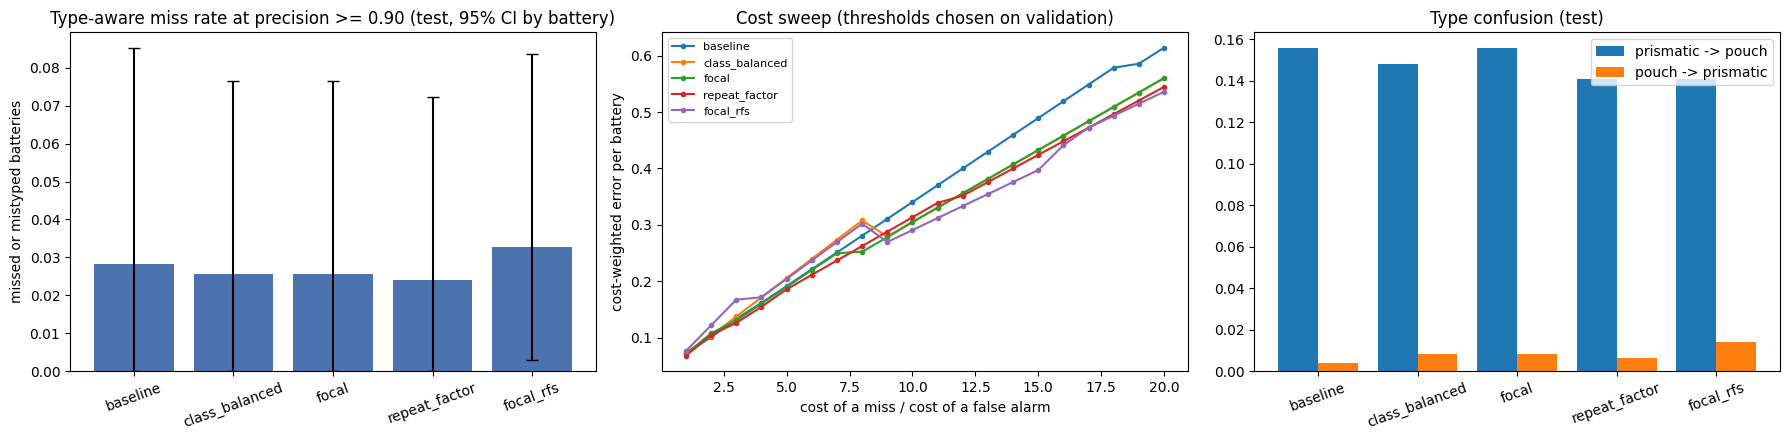

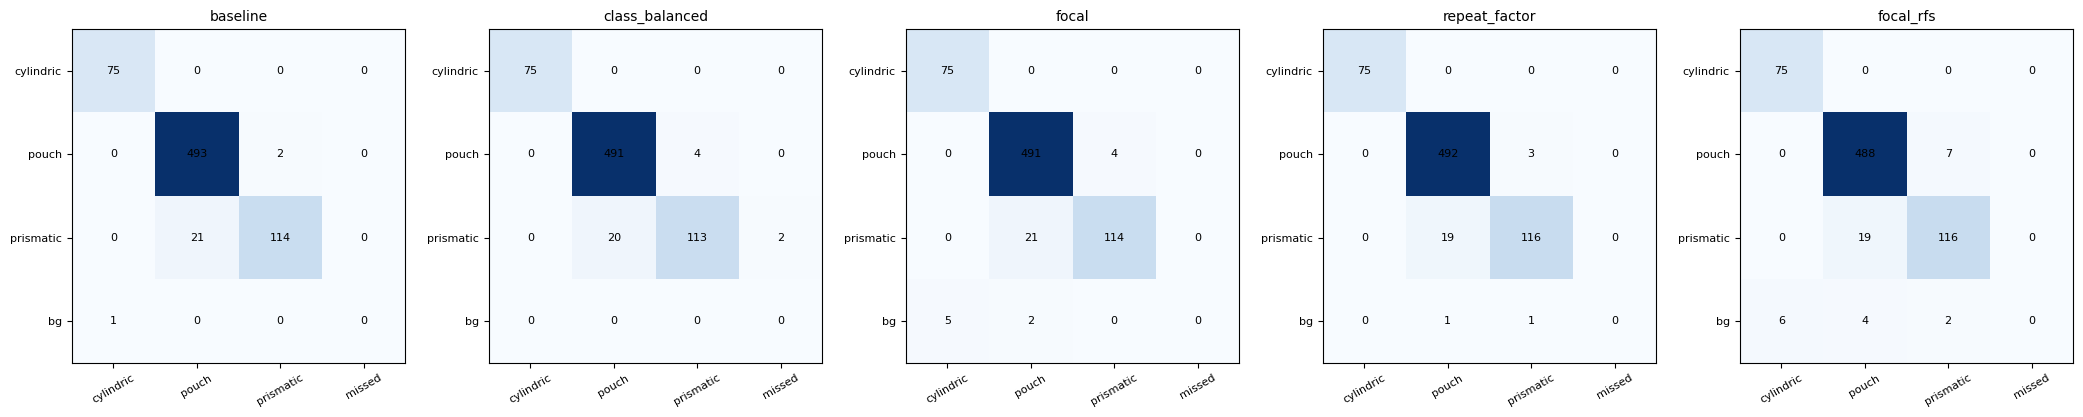

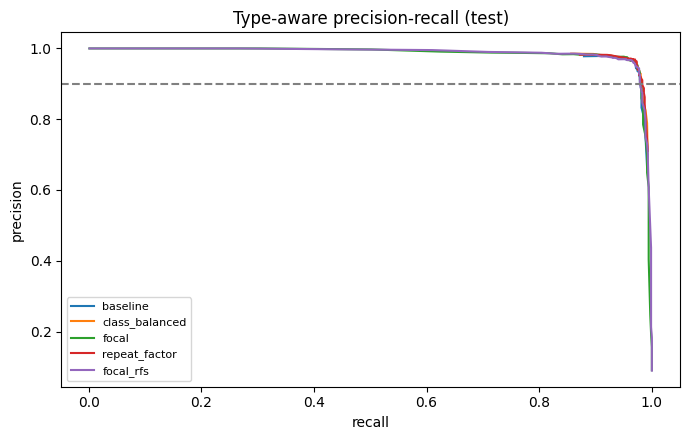

In [12]:
# ---- Comparison table + figures ----
names = list(results)
rows = []
for n in names:
    r = results[n]; ag, aw = r["safety"]["class_agnostic"], r["safety"]["class_aware"]
    rows.append({
        "variant": n, "mAP50": r["test_coco"]["mAP50"], "mAP50_95": r["test_coco"]["mAP50_95"],
        **{f"AP50_{c}": r["test_coco"]["per_class"][c]["AP50"] for c in CLASSES[1:]},
        "any_miss@P90": ag["test_at_thr"]["miss_rate"], "any_miss_CI": ag["miss_ci"],
        "type_miss@P90": aw["test_at_thr"]["miss_rate"], "type_miss_CI": aw["miss_ci"],
        "type_precision": aw["test_at_thr"]["precision"], "type_F1": aw["test_at_thr"]["f1"], "thr": aw["thr_from_val"],
        "type_CWE@10": aw["cost"][MISS_COST]["cwe_per_battery"] if MISS_COST in aw["cost"] else aw["cost"][str(MISS_COST)]["cwe_per_battery"],
        "prism_as_pouch": ag.get("prismatic_as_pouch"), "ECE": aw["ece"],
    })
json.dump(rows, open(os.path.join(OUT, "E2_summary.json"), "w"), indent=1, default=float)
hdr = f"{'variant':16s} {'mAP50':>6s} {'mAP':>6s} {'anyMiss':>8s} {'typeMiss':>9s} {'95% CI':>15s} {'prec':>6s} {'CWE10':>6s} {'pr->po':>7s} {'ECE':>6s}"
print(hdr); print("-" * len(hdr))
for r in rows:
    print(f"{r['variant']:16s} {r['mAP50']:6.3f} {r['mAP50_95']:6.3f} {r['any_miss@P90']:8.3f} {r['type_miss@P90']:9.3f} "
          f"[{r['type_miss_CI'][0]:.3f},{r['type_miss_CI'][1]:.3f}] {r['type_precision']:6.3f} {r['type_CWE@10']:6.3f} "
          f"{(r['prism_as_pouch'] or 0):7.3f} {r['ECE']:6.3f}")

def cost_of(r, c):
    d = r["safety"]["class_aware"]["cost"]
    return d[c] if c in d else d[str(c)]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
x = np.arange(len(names))
mr = [r["type_miss@P90"] for r in rows]
err = np.array([[r["type_miss@P90"] - r["type_miss_CI"][0], r["type_miss_CI"][1] - r["type_miss@P90"]] for r in rows]).T
ax[0].bar(x, mr, yerr=np.clip(err, 0, None), capsize=4, color="#4C72B0")
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=20); ax[0].set_ylabel("missed or mistyped batteries")
ax[0].set_title("Type-aware miss rate at precision >= 0.90 (test, 95% CI by battery)")
for n in names:
    ax[1].plot(COST_RATIOS, [cost_of(results[n], c)["cwe_per_battery"] for c in COST_RATIOS], "o-", ms=3, label=n)
ax[1].set_xlabel("cost of a miss / cost of a false alarm"); ax[1].set_ylabel("cost-weighted error per battery")
ax[1].set_title("Cost sweep (thresholds chosen on validation)"); ax[1].legend(fontsize=8)
ax[2].bar(x - 0.2, [r["prism_as_pouch"] or 0 for r in rows], 0.4, label="prismatic -> pouch")
ax[2].bar(x + 0.2, [results[n]["safety"]["class_agnostic"].get("pouch_as_prismatic", 0) for n in names], 0.4, label="pouch -> prismatic")
ax[2].set_xticks(x); ax[2].set_xticklabels(names, rotation=20); ax[2].legend(); ax[2].set_title("Type confusion (test)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E2_comparison.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4))
labels = CLASSES[1:] + ["bg"]
for ax_, n in zip(np.atleast_1d(axes), names):
    cm = np.array(results[n]["safety"]["class_agnostic"]["confusion"])
    ax_.imshow(cm, cmap="Blues")
    for i in range(K + 1):
        for j in range(K + 1):
            ax_.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
    ax_.set_xticks(range(K + 1)); ax_.set_xticklabels(labels[:-1] + ["missed"], rotation=30, fontsize=8)
    ax_.set_yticks(range(K + 1)); ax_.set_yticklabels(labels, fontsize=8); ax_.set_title(n, fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E2_confusion_matrices.png"), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for n in names:
    pr = results[n]["safety"]["class_aware"]["pr_curve_test"]
    ax.plot([p["recall"] for p in pr], [p["precision"] for p in pr], label=n)
ax.axhline(TARGET_PRECISION, ls="--", c="gray"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Type-aware precision-recall (test)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E2_pr_curves.png"), dpi=130); plt.show()

In [13]:
# ---- Zip results + figures (weights stay in OUT) and download ----
pack = "/content/E2_results" if os.path.isdir("/content") else "./E2_results"
os.makedirs(pack, exist_ok=True)
for f in os.listdir(OUT):
    if f.endswith(".json"):
        shutil.copy(os.path.join(OUT, f), pack)
shutil.copytree(FIG, os.path.join(pack, "figures"), dirs_exist_ok=True)
zip_path = shutil.make_archive(pack, "zip", pack)
print("Results zip:", zip_path, "| weights kept in", OUT)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

Results zip: /content/E2_results.zip | weights kept in /content/drive/MyDrive/dont_miss_the_battery/E2_safety


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>